# Group C — Oral Cancer Classification (Corrected)

This notebook corrects the supplied assignment without adding model families. It retains Logistic Regression, the 8–4 ANN with dropout, Decision Tree and Random Forest, and 12-fold stratified cross-validation.

**Task assumption:** predict the recorded diagnosis using information available before diagnosis/treatment. This is an educational dataset experiment, not a clinically validated diagnostic system. Dataset provenance and collection timing were not supplied; associations do not establish clinical validity.

## Corrections and evaluation scope
- Preserve the raw dataset and valid zeros; do not perform whole-dataset mean imputation.
- Exclude ID, Country, Tumor Size, Cancer Stage, Treatment Type, Survival Rate, Treatment Cost, Lost Workdays and Early Diagnosis. The latter seven may encode diagnosis, treatment or later outcomes; exclude them conservatively under the task assumption. Country/ID were already excluded in the original model inputs.
- Use the same 15 pre-diagnosis candidate features for every model. Validate labels and numeric values explicitly. No silent category-to-zero conversion.
- Fit scaling within each training fold. Reuse identical fold indices for all models.
- Fix ANN layer construction and train once for 5 epochs per fold (the explicitly written epoch setting in the original). Record all five epochs; never use the outer test fold for training validation or model selection.
- Report every fold and pooled out-of-fold (OOF) predictions for all rows. Final-fold plots are explicitly labeled.
- Keep existing tree hyperparameters. Increase Logistic Regression iteration allowance only to permit convergence; do not tune against CV results.
- Do not assert that Random Forest is best. Results are calculated by execution.

## Running on Windows / Anaconda
Place this notebook and `oral_cancer_prediction_dataset.csv` in the same folder. In Anaconda Prompt:
```
conda create -n oral_assignment python=3.11 -y
conda activate oral_assignment
python -m pip install pandas numpy scikit-learn matplotlib seaborn tensorflow jupyter
jupyter notebook
```
Open the notebook and select **Kernel → Restart & Run All**. The dependency installation cell below is optional; run it only if packages are missing. Full CV trains 48 models including 12 ANN fits. Saved outputs are evidence only for the dataset fingerprint and package versions shown below.


## Verification of this delivered copy
All code cells were executed sequentially in a fresh IPython process against the complete supplied 84,922-row dataset. All 48 fold fits completed, finite-input checks passed, and every record received exactly one OOF prediction per model. Outputs and plots below are from that execution. Standard Jupyter kernel startup was blocked by this host's socket restrictions; validation used IPython directly, with Matplotlib figures captured using the Agg backend. A Windows/Anaconda run was not performed.

| Model | Pooled OOF accuracy |
|---|---:|
| Logistic Regression | 49.6726% |
| ANN | 50.0848% |
| Decision Tree | 50.1319% |
| Random Forest | 50.1825% |

The observed No-diagnosis prevalence is 50.1319%. These results do not demonstrate useful discrimination; the fixed Decision Tree predicts only the majority class (Cancer recall = 0). No tuning was added to raise scores. The low scores are retained honestly. See the class reports for the consequences of each prediction pattern.


In [1]:
# Optional: uncomment in this kernel if dependencies are missing, then restart the kernel.
# %pip install pandas numpy scikit-learn matplotlib seaborn tensorflow


In [2]:
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '2')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '2')
from pathlib import Path
import hashlib
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from IPython.display import display
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

SEED = 42
N_SPLITS = 12
EPOCHS = 5
BATCH_SIZE = 256
tf.keras.utils.set_random_seed(SEED)
sns.set_theme(style='whitegrid', palette='Blues_r')
print('Python:', platform.python_version())
for package in ['pandas', 'numpy', 'scikit-learn', 'tensorflow', 'matplotlib', 'seaborn']:
    try:
        print(package, importlib.metadata.version(package))
    except importlib.metadata.PackageNotFoundError:
        print(package, 'distribution name unavailable; imported successfully')


Python: 3.12.14
pandas 2.2.3
numpy 2.3.5
scikit-learn 1.8.0
tensorflow distribution name unavailable; imported successfully
matplotlib 3.10.8
seaborn 0.13.2


## 1. Load and validate the raw dataset
No rows are silently dropped. Invalid input stops execution with an informative error. The supplied dataset has no missing values, so no imputation is required.

In [3]:
DATA_PATH = Path('oral_cancer_prediction_dataset.csv')
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Place the CSV beside this notebook or update DATA_PATH. Current directory: {Path.cwd()}')
raw = pd.read_csv(DATA_PATH)
TARGET = 'Oral Cancer (Diagnosis)'
BINARY = ['Tobacco Use', 'Alcohol Consumption', 'HPV Infection', 'Betel Quid Use',
          'Chronic Sun Exposure', 'Poor Oral Hygiene', 'Family History of Cancer',
          'Compromised Immune System', 'Oral Lesions', 'Unexplained Bleeding',
          'Difficulty Swallowing', 'White or Red Patches in Mouth']
FEATURES = ['Age', 'Gender', *BINARY, 'Diet (Fruits & Vegetables Intake)']
EXCLUDED = ['ID', 'Country', 'Tumor Size (cm)', 'Cancer Stage', 'Treatment Type',
            'Survival Rate (5-Year, %)', 'Cost of Treatment (USD)',
            'Economic Burden (Lost Workdays per Year)', 'Early Diagnosis']
missing = sorted(set(FEATURES + [TARGET]) - set(raw.columns))
if missing:
    raise ValueError(f'Missing required columns: {missing}')
if raw.empty or raw[FEATURES + [TARGET]].isna().any().any():
    raise ValueError('Empty dataset or missing required values. Resolve explicitly before training.')
if raw.duplicated().any() or ('ID' in raw and raw['ID'].duplicated().any()):
    raise ValueError('Duplicate rows or IDs found. Resolve repeated patients before row-wise CV.')
print('Dataset SHA256:', hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
print('Shape:', raw.shape)
display(raw[TARGET].value_counts().rename_axis('Diagnosis').to_frame('Count'))
display(raw.isna().sum().to_frame('Missing values'))
print('Excluded from prediction:', EXCLUDED)


Dataset SHA256: 3070535bfa747261a97901018a6c9391ac97356cba1c4fd9dd63c99e5f15763b
Shape: (84922, 25)
Excluded from prediction: ['ID', 'Country', 'Tumor Size (cm)', 'Cancer Stage', 'Treatment Type', 'Survival Rate (5-Year, %)', 'Cost of Treatment (USD)', 'Economic Burden (Lost Workdays per Year)', 'Early Diagnosis']


,Count
Diagnosis,
No,42573
Yes,42349


,Missing values
ID,0
Country,0
Age,0
Gender,0
Tobacco Use,0
Alcohol Consumption,0
HPV Infection,0
Betel Quid Use,0
Chronic Sun Exposure,0
Poor Oral Hygiene,0


In [4]:
def encode_checked(series, mapping):
    cleaned = series.astype('string').str.strip()
    unknown = sorted(set(cleaned.dropna()) - set(mapping))
    if unknown or cleaned.isna().any():
        raise ValueError(f'{series.name}: unknown/missing categories: {unknown}')
    return cleaned.map(mapping).astype('int64')

X = raw[FEATURES].copy()
X['Age'] = pd.to_numeric(X['Age'], errors='raise')
X['Gender'] = encode_checked(X['Gender'], {'Female': 0, 'Male': 1})
for column in BINARY:
    X[column] = encode_checked(X[column], {'No': 0, 'Yes': 1})
# Preserve the original explicit dietary ordering.
X['Diet (Fruits & Vegetables Intake)'] = encode_checked(
    X['Diet (Fruits & Vegetables Intake)'], {'Low': 0, 'Moderate': 1, 'High': 2})
y = encode_checked(raw[TARGET], {'No': 0, 'Yes': 1})
if not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError('Non-finite feature values detected.')
if set(y.unique()) != {0, 1} or y.value_counts().min() < N_SPLITS:
    raise ValueError('Both classes need at least N_SPLITS observations.')
print('Validated feature matrix:', X.shape)
display(X.head())


Validated feature matrix: (84922, 15)


,Age,Gender,Tobacco Use,Alcohol Consumption,HPV Infection,Betel Quid Use,Chronic Sun Exposure,Poor Oral Hygiene,Family History of Cancer,Compromised Immune System,Oral Lesions,Unexplained Bleeding,Difficulty Swallowing,White or Red Patches in Mouth,Diet (Fruits & Vegetables Intake)
0,36,0,1,1,1,0,0,1,0,0,0,0,0,0,0
1,64,1,1,1,1,0,1,1,0,0,0,1,0,0,2
2,37,0,0,1,0,0,1,1,0,0,0,0,0,1,1
3,55,1,1,1,0,1,0,1,0,0,1,0,0,0,1
4,68,1,0,0,0,0,0,1,0,0,0,0,0,0,2


## 2. Exploratory plots
Plots use unmodified source measurements. The heatmap includes only encoded candidate inputs and the target; correlation is descriptive, not causal.

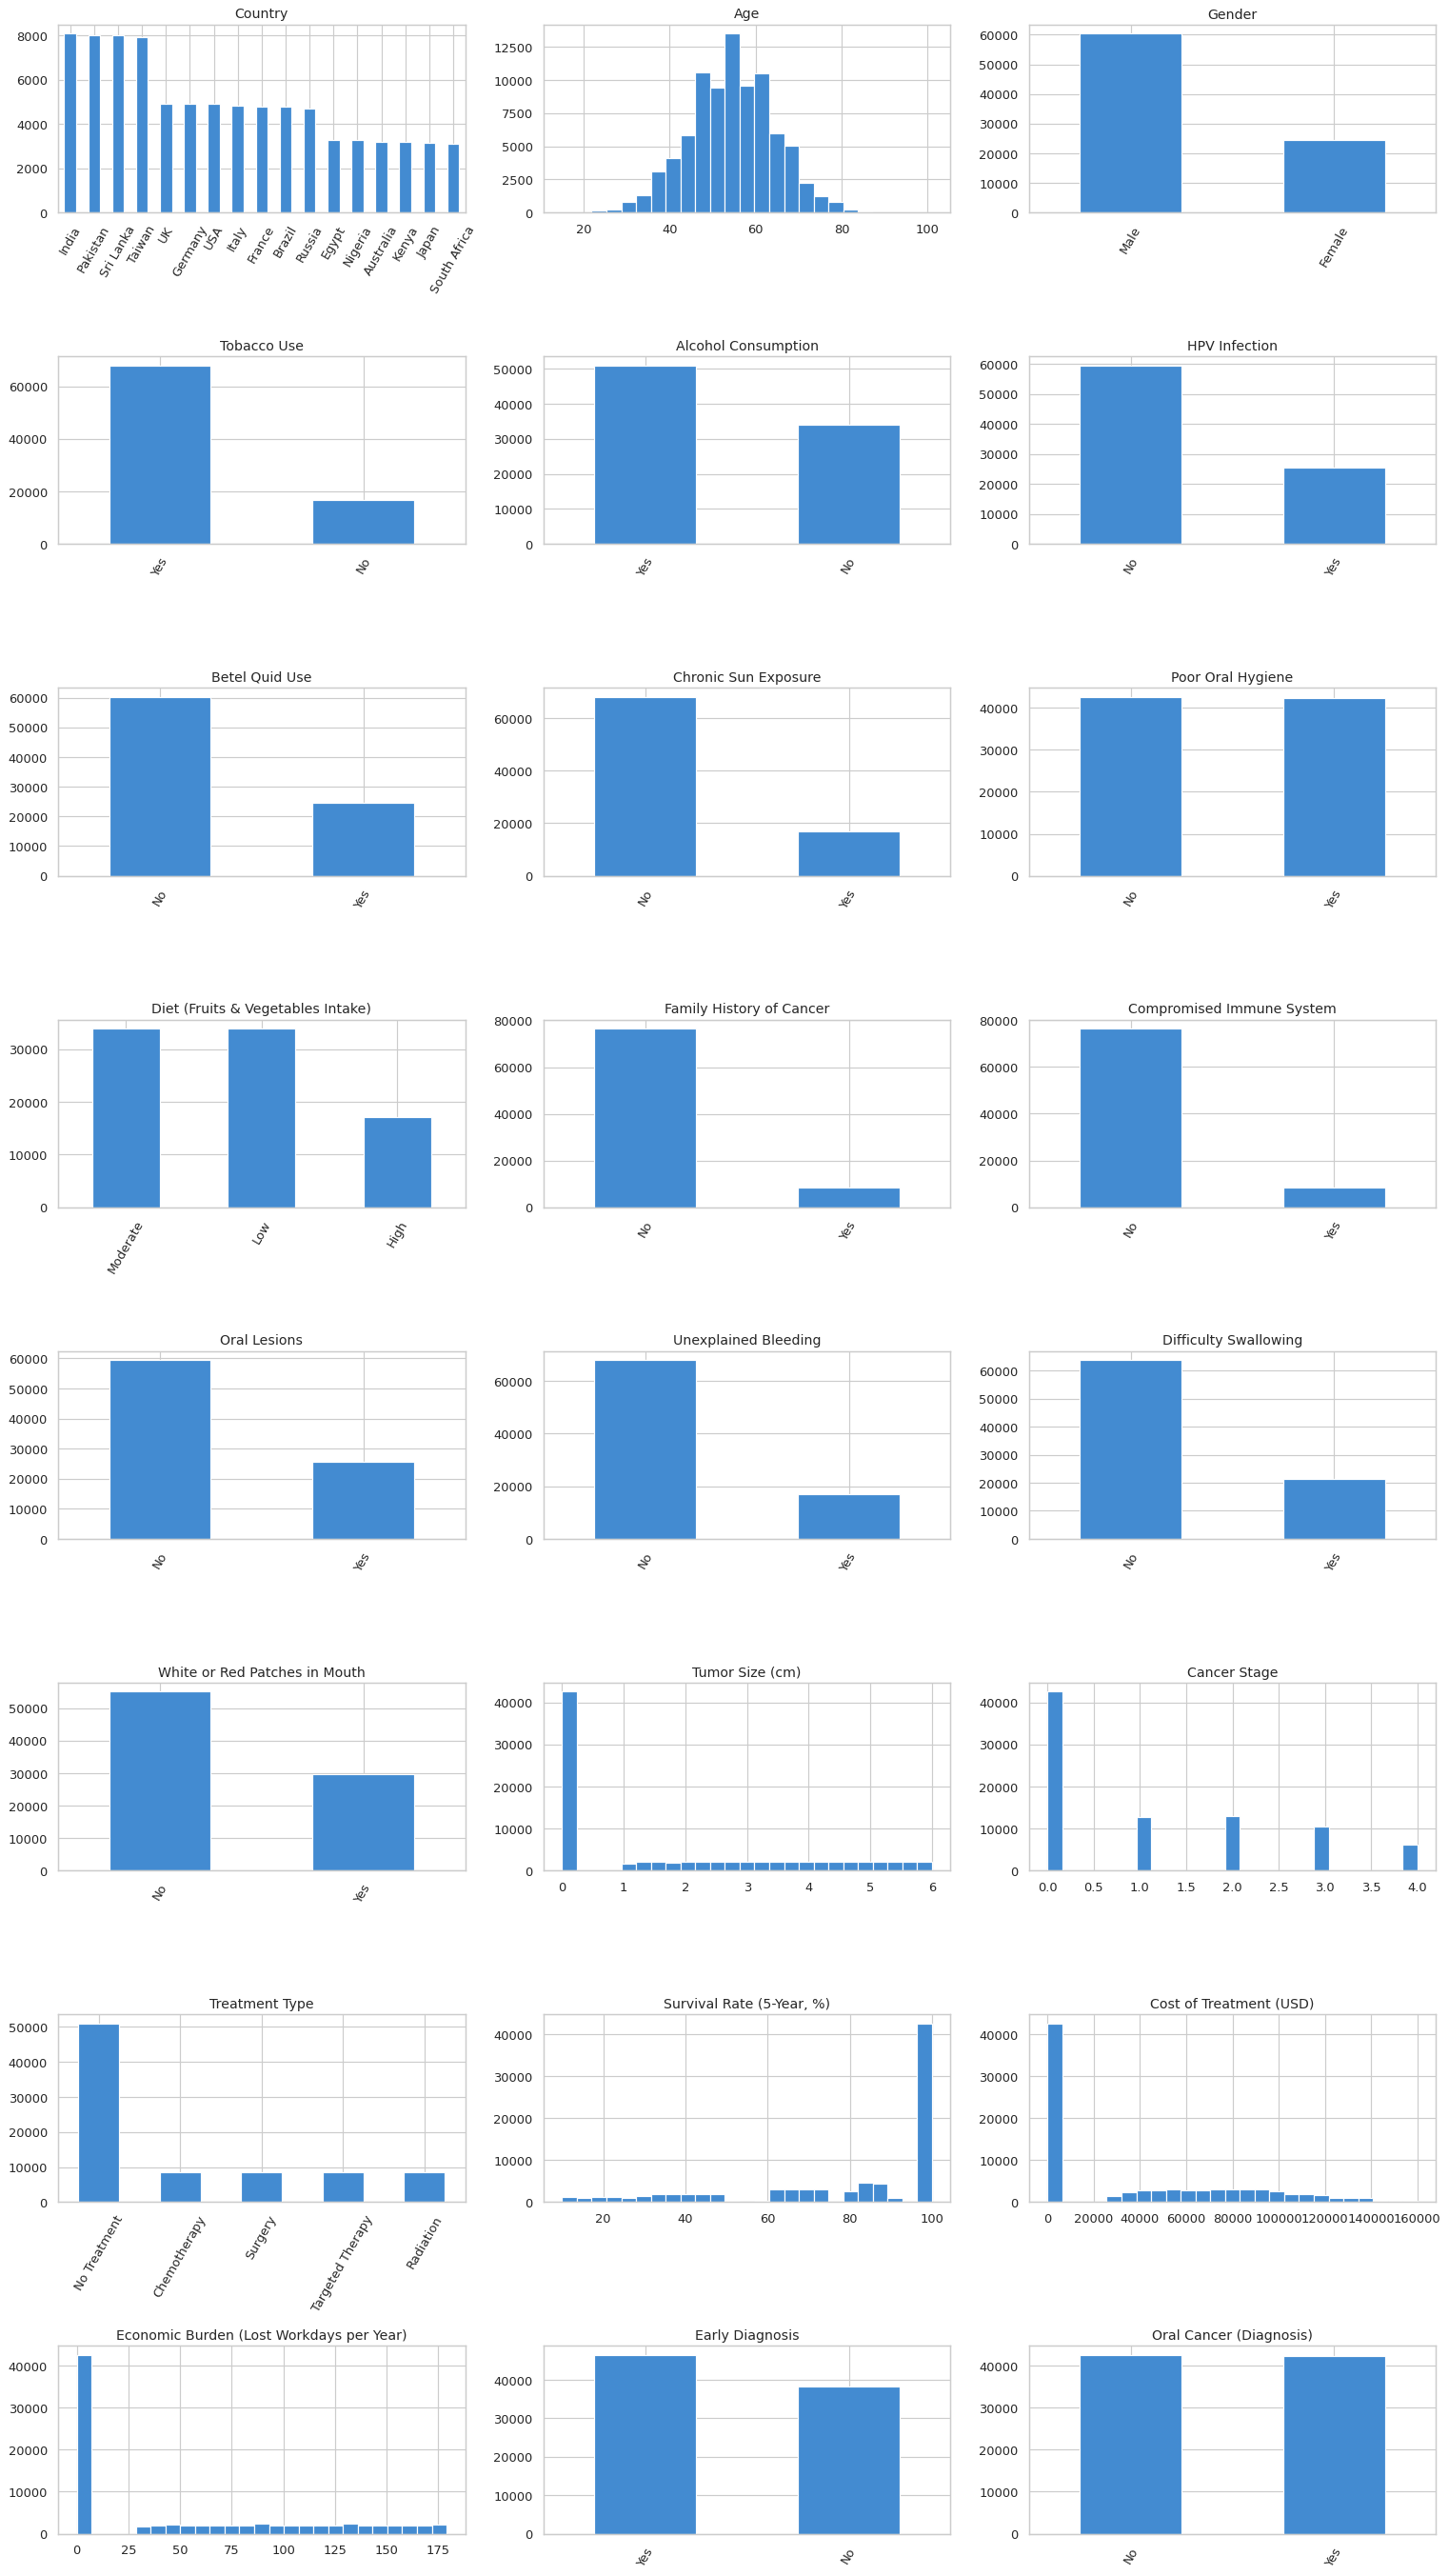

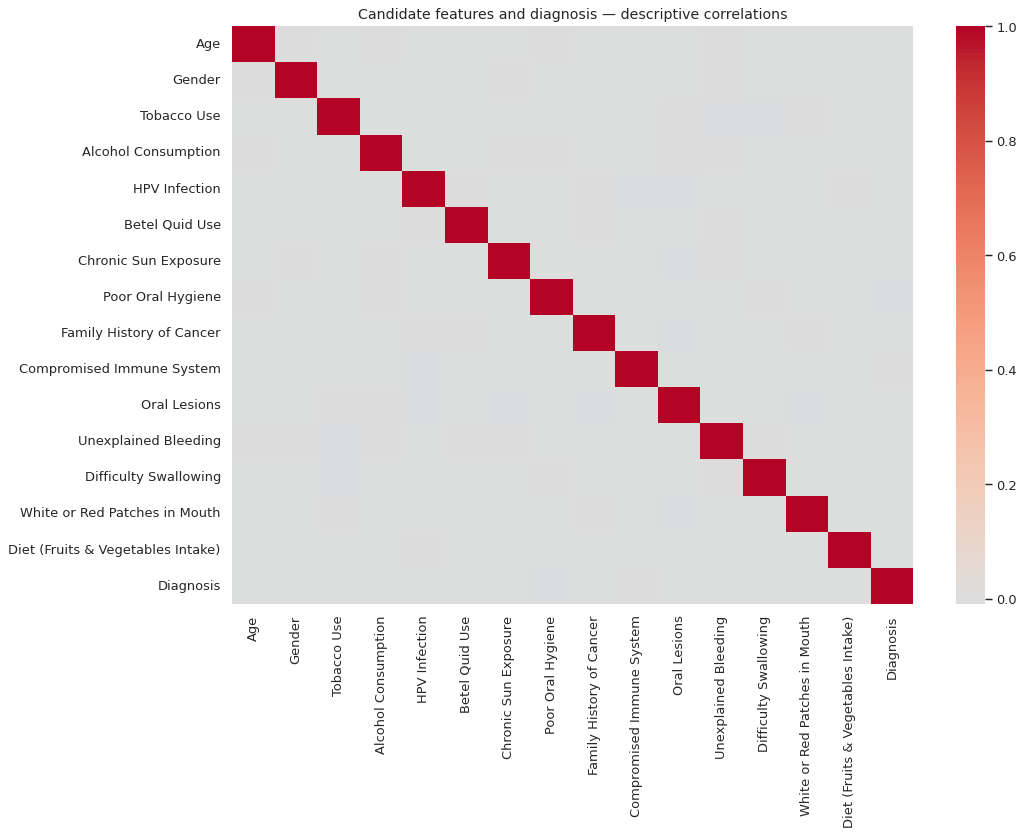

In [5]:
columns = raw.drop(columns=['ID'], errors='ignore').columns.tolist()
fig, axes = plt.subplots(int(np.ceil(len(columns)/3)), 3, figsize=(18, 4*int(np.ceil(len(columns)/3))))
for ax, column in zip(axes.flat, columns):
    if pd.api.types.is_numeric_dtype(raw[column]):
        ax.hist(raw[column].dropna(), bins=25, color='#438bd1', edgecolor='white')
    else:
        raw[column].value_counts().plot.bar(ax=ax, color='#438bd1')
        ax.tick_params(axis='x', rotation=60)
    ax.set_title(column)
    ax.set_xlabel('')
for ax in list(axes.flat)[len(columns):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(X.assign(Diagnosis=y).corr(), cmap='coolwarm', center=0, ax=ax)
ax.set_title('Candidate features and diagnosis — descriptive correlations')
plt.tight_layout()
plt.show()


## 3. Cross-validation
All models use the same folds and inputs. Each row is predicted exactly once by a model that did not train on that row. Scaling is learned only on each training fold. Fixed settings are not selected using outer-fold scores.

ANN uses fresh weights and a fold-specific seed. The outer test fold is evaluated only after fitting. Loss plots therefore show training loss only. Five epochs are not a claim of optimal convergence. Reproducibility can still vary across hardware/library versions.


In [6]:
folds = list(StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(X, y))
MODELS = ['Logistic Regression', 'ANN', 'Decision Tree', 'Random Forest']
oof = {name: np.full(len(y), -1, dtype=int) for name in MODELS}
coverage = {name: np.zeros(len(y), dtype=int) for name in MODELS}
fold_rows, ann_histories, last_models = [], [], {}

def make_ann(n_features):
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(n_features,)),
        tf.keras.layers.Dense(8, activation='relu'),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(4, activation='relu'),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(1, activation='sigmoid')])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

for name in MODELS:
    for fold, (train_idx, test_idx) in enumerate(folds, start=1):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        scaler = None
        if name in ['Logistic Regression', 'ANN', 'Random Forest']:
            scaler = StandardScaler()
            train_values = scaler.fit_transform(X_train).astype('float32')
            test_values = scaler.transform(X_test).astype('float32')
        else:
            train_values, test_values = X_train, X_test
        if name == 'Logistic Regression':
            model = LogisticRegression(max_iter=1000, random_state=SEED)
        elif name == 'Decision Tree':
            model = DecisionTreeClassifier(max_depth=4, min_samples_split=20,
                min_samples_leaf=10, max_leaf_nodes=10, max_features=0.5,
                ccp_alpha=0.01, random_state=SEED)
        elif name == 'Random Forest':
            model = RandomForestClassifier(n_estimators=20, max_depth=12, random_state=SEED)
        else:
            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(SEED + fold)
            model = make_ann(X.shape[1])
        if name == 'ANN':
            # Limit tf.data threads for portable execution on small machines.
            options = tf.data.Options()
            options.threading.private_threadpool_size = 1
            train_ds = tf.data.Dataset.from_tensor_slices(
                (train_values, y_train.to_numpy(dtype='float32')))
            train_ds = train_ds.shuffle(len(train_idx), seed=SEED + fold).batch(BATCH_SIZE).with_options(options)
            history = model.fit(train_ds, epochs=EPOCHS, verbose=0)
            ann_histories.append(history.history)
            probabilities = model(test_values, training=False).numpy().ravel()
            predictions = (probabilities > 0.5).astype(int)
        else:
            model.fit(train_values, y_train)
            predictions = model.predict(test_values)
        oof[name][test_idx] = predictions
        coverage[name][test_idx] += 1
        fold_rows.append({'Model': name, 'Fold': fold,
            'Accuracy': accuracy_score(y_test, predictions),
            'Precision': precision_score(y_test, predictions, zero_division=0),
            'Recall': recall_score(y_test, predictions, zero_division=0),
            'F1': f1_score(y_test, predictions, zero_division=0)})
        print(f'{name} | fold {fold:02d}/{N_SPLITS} | accuracy={fold_rows[-1]["Accuracy"]:.4f}', flush=True)
    last_models[name] = {'model': model, 'scaler': scaler}

for name in MODELS:
    assert np.all(coverage[name] == 1), f'OOF coverage error: {name}'
    assert set(np.unique(oof[name])).issubset({0, 1})
fold_results = pd.DataFrame(fold_rows)
print('All models completed; every row has exactly one out-of-fold prediction per model.')


Logistic Regression | fold 01/12 | accuracy=0.4968
Logistic Regression | fold 02/12 | accuracy=0.4994
Logistic Regression | fold 03/12 | accuracy=0.4972
Logistic Regression | fold 04/12 | accuracy=0.4922
Logistic Regression | fold 05/12 | accuracy=0.4941
Logistic Regression | fold 06/12 | accuracy=0.4915
Logistic Regression | fold 07/12 | accuracy=0.4978
Logistic Regression | fold 08/12 | accuracy=0.5054
Logistic Regression | fold 09/12 | accuracy=0.4933
Logistic Regression | fold 10/12 | accuracy=0.5004
Logistic Regression | fold 11/12 | accuracy=0.4927
Logistic Regression | fold 12/12 | accuracy=0.5000
ANN | fold 01/12 | accuracy=0.4978
ANN | fold 02/12 | accuracy=0.4989
ANN | fold 03/12 | accuracy=0.4988
ANN | fold 04/12 | accuracy=0.4985
ANN | fold 05/12 | accuracy=0.5001
ANN | fold 06/12 | accuracy=0.5025
ANN | fold 07/12 | accuracy=0.5013
ANN | fold 08/12 | accuracy=0.5013
ANN | fold 09/12 | accuracy=0.4995
ANN | fold 10/12 | accuracy=0.5001
ANN | fold 11/12 | accuracy=0.5095
ANN

/root/.local/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
/root/.local/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
/root/.local/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
/root/.local/

## 4. Full cross-validation comparison
Precision, recall and F1 treat Cancer (1) as positive; zero-division scores are set to 0. Fold standard deviation is descriptive variation, not a confidence interval. Pooled OOF accuracy weights rows equally; mean fold accuracy weights folds equally. No independent external test set was supplied.

Logistic Regression — pooled out-of-fold classification report
              precision    recall  f1-score   support

   No Cancer       0.50      0.63      0.56     42573
      Cancer       0.49      0.36      0.42     42349

    accuracy                           0.50     84922
   macro avg       0.50      0.50      0.49     84922
weighted avg       0.50      0.50      0.49     84922

ANN — pooled out-of-fold classification report
              precision    recall  f1-score   support

   No Cancer       0.50      0.62      0.55     42573
      Cancer       0.50      0.38      0.43     42349

    accuracy                           0.50     84922
   macro avg       0.50      0.50      0.49     84922
weighted avg       0.50      0.50      0.49     84922

Decision Tree — pooled out-of-fold classification report
              precision    recall  f1-score   support

   No Cancer       0.50      1.00      0.67     42573
      Cancer       0.00      0.00      0.00     42349

    accuracy   

,Model,Fold,Accuracy,Precision,Recall,F1
0,Logistic Regression,1,0.496821,0.493860,0.364693,0.419560
1,Logistic Regression,2,0.499364,0.497196,0.351658,0.411950
2,Logistic Regression,3,0.497245,0.494790,0.390196,0.436312
3,Logistic Regression,4,0.492158,0.487666,0.364126,0.416937
4,Logistic Regression,5,0.494136,0.489051,0.322754,0.388870
5,Logistic Regression,6,0.491451,0.485094,0.322754,0.387613
6,Logistic Regression,7,0.497810,0.495295,0.372910,0.425477
7,Logistic Regression,8,0.505440,0.505706,0.364126,0.423394
8,Logistic Regression,9,0.493288,0.488784,0.351941,0.409226
9,Logistic Regression,10,0.500353,0.498824,0.360340,0.418421


Accuracy           Precision  ...    Recall        F1          
                         mean       std      mean  ...       std      mean       std
Model                                              ...                              
Logistic Regression  0.496726  0.004178  0.493680  ...  0.027189  0.415325  0.018375
ANN                  0.500848  0.003074  0.413372  ...  0.463360  0.289091  0.302218
Decision Tree        0.501319  0.000046  0.000000  ...  0.000000  0.000000  0.000000
Random Forest        0.501825  0.005711  0.500519  ...  0.012226  0.488346  0.008370

[4 rows x 8 columns]

,OOF Accuracy,OOF Precision,OOF Recall,OOF F1
Model,,,,
Logistic Regression,0.496726,0.493672,0.359206,0.415839
ANN,0.500848,0.499380,0.380694,0.432034
Decision Tree,0.501319,0.000000,0.000000,0.000000
Random Forest,0.501825,0.500533,0.476847,0.488403


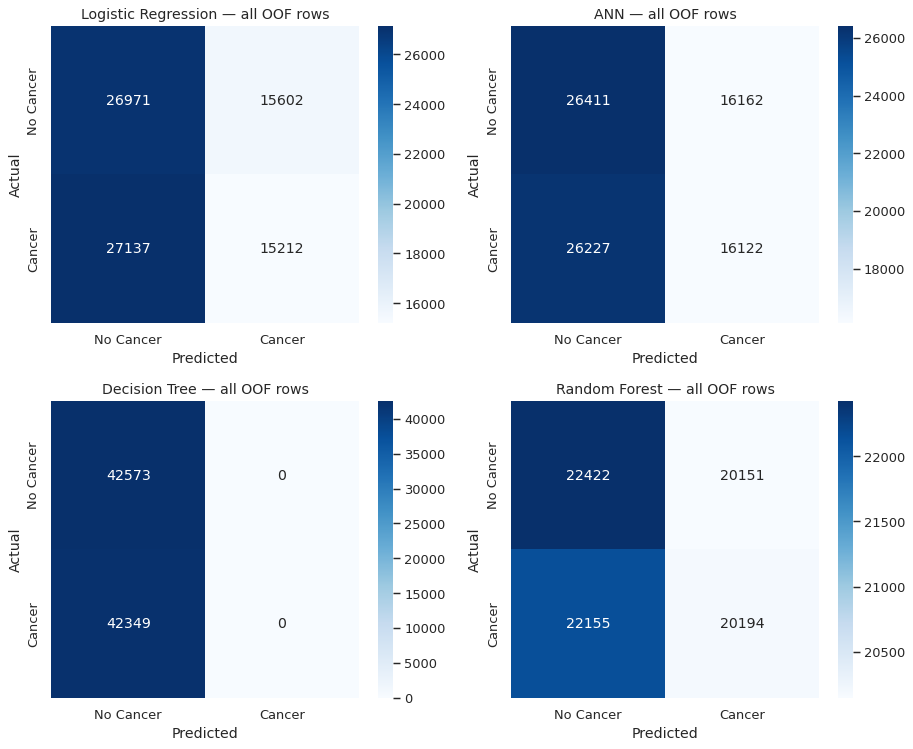

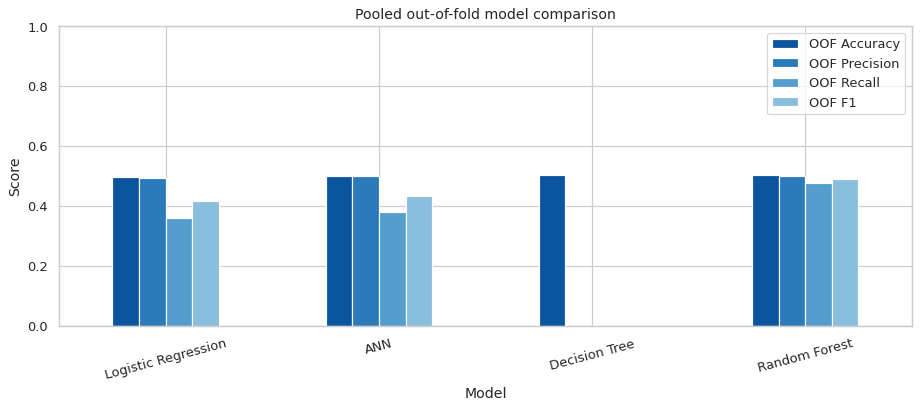

In [7]:
display(fold_results)
cv_summary = fold_results.groupby('Model', sort=False)[['Accuracy', 'Precision', 'Recall', 'F1']].agg(['mean', 'std'])
display(cv_summary)
summary_rows = []
confusion_matrices = {}
for name in MODELS:
    predictions = oof[name]
    summary_rows.append({'Model': name, 'OOF Accuracy': accuracy_score(y, predictions),
        'OOF Precision': precision_score(y, predictions, zero_division=0),
        'OOF Recall': recall_score(y, predictions, zero_division=0),
        'OOF F1': f1_score(y, predictions, zero_division=0)})
    confusion_matrices[name] = confusion_matrix(y, predictions, labels=[0, 1])
    assert confusion_matrices[name].sum() == len(y)
    print(name, '— pooled out-of-fold classification report')
    print(classification_report(y, predictions, labels=[0, 1],
          target_names=['No Cancer', 'Cancer'], zero_division=0))
summary = pd.DataFrame(summary_rows).set_index('Model')
display(summary)
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, name in zip(axes.flat, MODELS):
    sns.heatmap(confusion_matrices[name], annot=True, fmt='d', cmap='Blues',
                xticklabels=['No Cancer', 'Cancer'], yticklabels=['No Cancer', 'Cancer'], ax=ax)
    ax.set(title=f'{name} — all OOF rows', xlabel='Predicted', ylabel='Actual')
plt.tight_layout()
plt.show()
summary.plot.bar(figsize=(11, 5), ylim=(0, 1), rot=15, title='Pooled out-of-fold model comparison')
plt.ylabel('Score')
plt.tight_layout()
plt.show()


## 5. Training and tree visualizations
ANN curves contain the complete single-fit history for each fold. Tree figures show the final fold models only; these are not models refitted on all rows. RF thresholds are in standardized units because the original RF scaling is retained. RF visualization is truncated for readability.

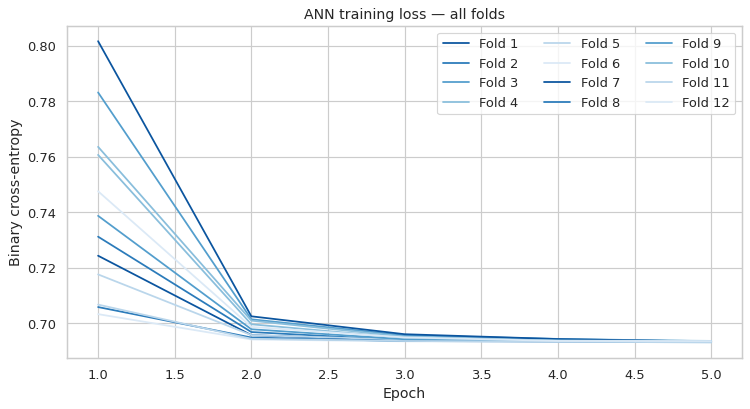

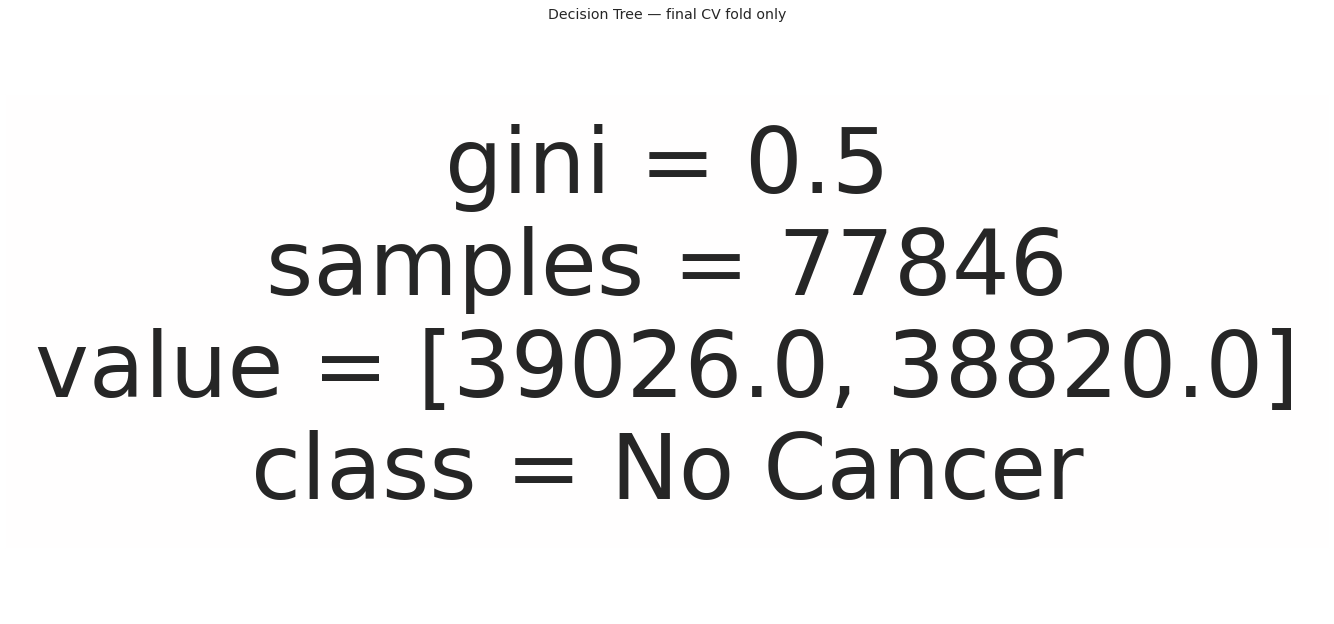

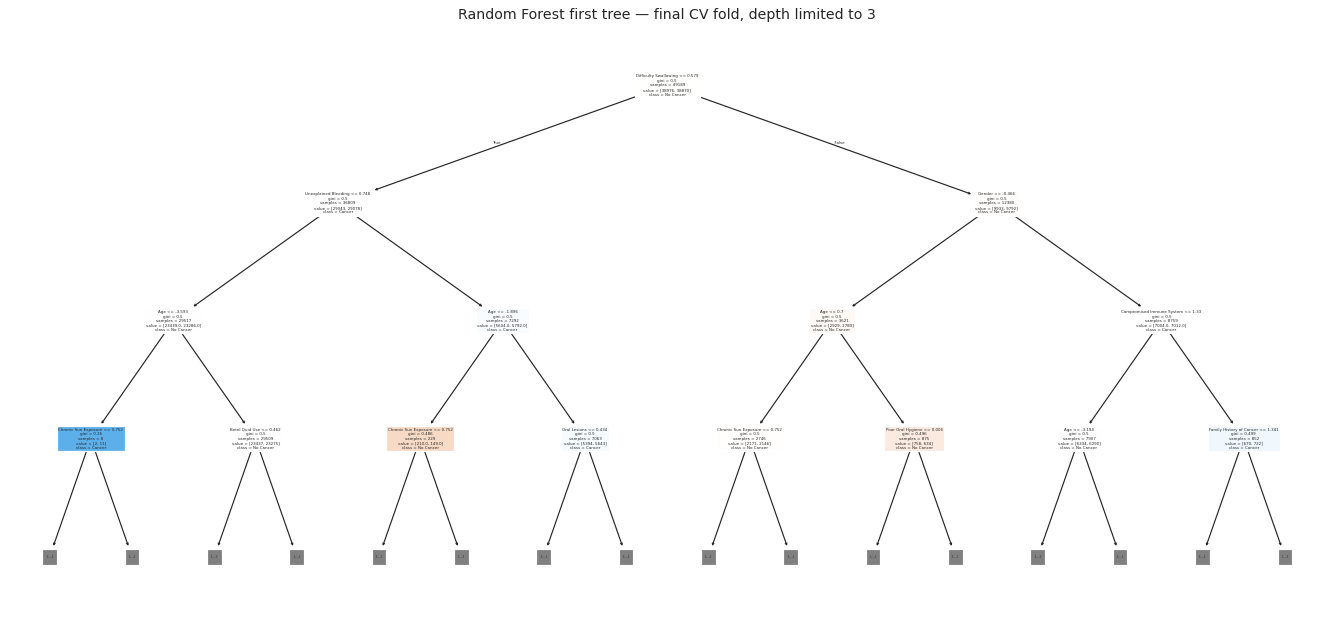

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
for fold, history in enumerate(ann_histories, 1):
    assert len(history['loss']) == EPOCHS
    ax.plot(range(1, EPOCHS+1), history['loss'], label=f'Fold {fold}')
ax.set(title='ANN training loss — all folds', xlabel='Epoch', ylabel='Binary cross-entropy')
ax.legend(ncol=3)
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(20, 9))
plot_tree(last_models['Decision Tree']['model'], feature_names=FEATURES,
          class_names=['No Cancer', 'Cancer'], filled=True, ax=ax)
ax.set_title('Decision Tree — final CV fold only')
plt.show()
fig, ax = plt.subplots(figsize=(20, 9))
plot_tree(last_models['Random Forest']['model'].estimators_[0], feature_names=FEATURES,
          class_names=['No Cancer', 'Cancer'], max_depth=3, filled=True, ax=ax)
ax.set_title('Random Forest first tree — final CV fold, depth limited to 3')
plt.show()


## Interpretation and limitations
Removing treatment/outcome information may substantially reduce accuracy. That is not a reason to restore leaked inputs. Scores around 50% on this approximately balanced dataset would indicate little demonstrated predictive signal under this setup. Do not claim clinical usefulness or a superior model from a small score difference.

No dataset source, patient-group structure, collection dates or external cohort was provided. Row-wise stratified CV assumes independent observations; unique IDs alone cannot prove independence. The fixed feature meanings and pre-diagnosis availability require source verification. This notebook corrects executable and evaluation issues, but does not establish medical validity.

There is no hyperparameter search, new model, clinical recommendation or dashboard in this corrected assignment. The models retained in memory are the final CV-fold models, not deployment artifacts.
